# Étape 1 – Choix de l'architecture du réseau

**Contexte.** Le réseau de neurones doit remplacer la méthode de Fourier pendant la calibration du modèle de
Heston : à partir des 5 paramètres (v0, θ, κ, ξ, ρ), il prédit la surface de volatilité implicite sur une grille
de 8 maturités × 11 strikes. Pour être utile, il doit être à la fois précis et nettement plus rapide que
Fourier, qui sert à calculer chaque surface pendant la calibration.

**Objectif.** Choisir la taille du réseau. Nous comparons 10 architectures : 2, 4 ou 6 couches cachées de 32, 128
ou 512 neurones, plus le réseau 4 × 30 de Horvath et al. (2021), qui sert de référence.

**Méthode.** Seule l'architecture change : toutes sont entraînées de la même façon (Adam, initialisation He,
activation ELU, 200 époques, batch de 32), sur le même découpage des données (80 % entraînement, 10 %
validation, 10 % test). Chaque architecture est entraînée avec **5 graines** différentes, pour mesurer la
variabilité des résultats. Les choix se font sur la validation ; le test ne sert qu'aux chiffres finaux.
L'erreur est mesurée en points de base de volatilité (1 pb = 0,01 %).

**Plan.**
1. Chargement des données et découpage.
2. Choix du taux d'apprentissage de référence.
3. Entraînement des 10 architectures.
4. Mesure des temps de réponse, comparés à Fourier.
5. Résultats : courbes d'apprentissage et tableau des erreurs.
6. Seuil de vitesse et choix de l'architecture.

**Configuration.** Nous chargeons les règles communes (`configs/base.yaml`) et la liste des 10 architectures.

In [5]:
import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from heston_nn.config import load_config, repo_path
from heston_nn.data.dataset import check_dataset, load_dataset
from heston_nn.data.split import prepare_data
from heston_nn.experiments import collect_results, my_share, run_configs, summarize
from heston_nn.models.mlp import build_model, make_predict_fn
from heston_nn.plots import plot_error_vs_time, show_results
from heston_nn.timing.benchmark import measure_time
from heston_nn.training.train import compile_train, evaluate_bp

cfg = load_config("configs/base.yaml")    # règles communes : 200 époques, batch 32, Adam, He, ELU

MACHINE_ID = 0      # 0, 1, 2 ou 3 : chacun met le sien
N_MACHINES = 4

config_paths = sorted(repo_path("configs", "etape1").glob("*.yaml"))   # les 10 architectures
print(len(config_paths), "architectures :", [p.stem for p in config_paths])

10 architectures : ['arch_2x128', 'arch_2x32', 'arch_2x512', 'arch_4x128', 'arch_4x30', 'arch_4x32', 'arch_4x512', 'arch_6x128', 'arch_6x32', 'arch_6x512']


## 1. Données
Nous chargeons `data/surfaces.npz`, vérifions les données, puis les découpons en 80 / 10 / 10 (graine 42)
et les normalisons à partir de l'entraînement seulement. Les NaN de Y sont gardés : la perte les ignore.

In [6]:
X, Y = load_dataset(repo_path("data", "surfaces.npz"))
print(check_dataset(X, Y, cfg))           # vérifie les données et compte les NaN

prepared = prepare_data(X, Y, cfg)        # (données normalisées, x_scaler, y_scaler)
scaled, x_scaler, y_scaler = prepared
for part in ["train", "val", "test"]:
    print(part, scaled[part][0].shape)

{'n_surfaces': 50000, 'n_surfaces_with_nan': 28078, 'n_nan_points': 83827, 'share_nan_points': 0.01905159090909091}
train (40000, 5)
val (5000, 5)
test (5000, 5)


## 2. Taux d'apprentissage de référence
Nous procédons avec une boucle sur les réglages : chaque essai est rangé dans `results`, puis tracé avec
`show_results`. Nous entraînons le réseau 4 × 30 avec trois taux d'apprentissage (1e-2, 1e-3 et 1e-4), gardons
le meilleur sur la validation et l'écrivons dans la configuration (`lr` dans `configs/base.yaml`).

Adam - 0.01... WARNING:tensorflow:TensorFlow GPU support is not available on native Windows for TensorFlow >= 2.11. Even if CUDA/cuDNN are installed, GPU will not be used. Please use WSL2 or the TensorFlow-DirectML plugin.


entraînement:   0%|          | 0/200 [00:00<?, ?époque/s]

Adam - 0.001... 

entraînement:   0%|          | 0/200 [00:00<?, ?époque/s]

Adam - 0.0001... 

entraînement:   0%|          | 0/200 [00:00<?, ?époque/s]

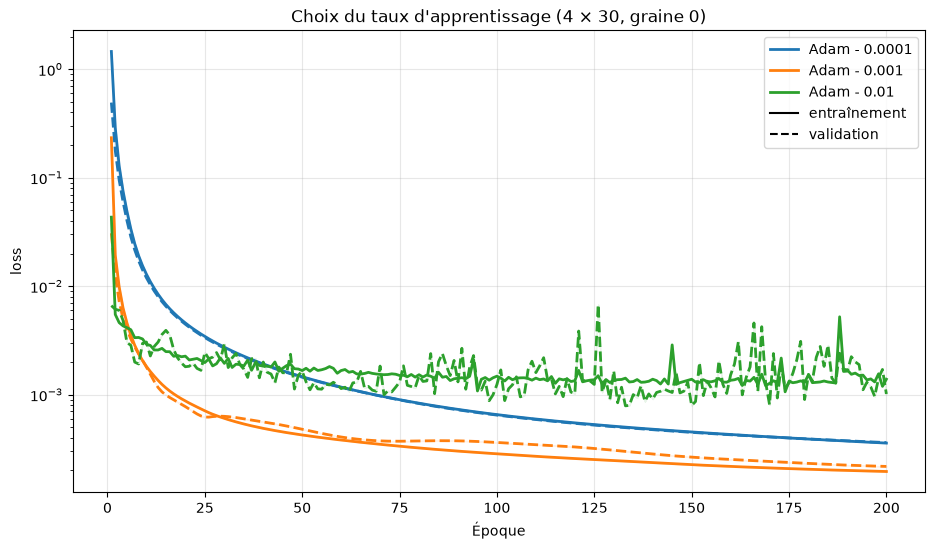

meilleur taux : 0.001 -> à écrire dans configs/base.yaml


,lr,val_mean_bp,val_max_bp,best_epoch
0,0.0100,14.258213,280.581216,133
1,0.0010,7.645863,127.610806,200
2,0.0001,9.192095,213.354281,200


In [3]:
ref_cfg = load_config("configs/etape1/arch_4x30.yaml")   # réseau de référence 4 × 30
learning_rates = [1e-2, 1e-3, 1e-4]
lr_results = []

for learning_rate in learning_rates:
    label = f"Adam - {learning_rate}"                      
    print(f"{label}...", end=" ")

    train_cfg = copy.deepcopy(ref_cfg["train"])
    train_cfg["lr"] = learning_rate                        # seul le taux change

    model, history = compile_train(ref_cfg["model"], train_cfg, seed=0, scaled=scaled)
    val_mean, val_max = evaluate_bp(model, *scaled["val"], y_scaler)   # erreurs en pb, validation

    lr_results.append({"type": label, "history": history, "lr": learning_rate,
                       "val_mean_bp": val_mean, "val_max_bp": val_max,
                       "best_epoch": int(history["val_loss"].idxmin()) + 1})
print()

show_results(lr_results, metric_name="loss", title="Choix du taux d'apprentissage (4 × 30, graine 0)",
             save_path=repo_path("results", "figures", "etape1_taux.png"))
plt.show()

lr_table = pd.DataFrame(lr_results)[["lr", "val_mean_bp", "val_max_bp", "best_epoch"]]
lr_table.to_csv(repo_path("results", "etape1_taux.csv"), index=False)
print("meilleur taux :", lr_table.loc[lr_table["val_mean_bp"].idxmin(), "lr"], "-> à écrire dans configs/base.yaml")
lr_table

## 3. Entraînement des 10 architectures
Nous allons lancer l'entraînement avec d'abord un essai court : il mesure le temps d'une époque pour la plus
petite et la plus grosse architecture. Cela nous permet de savoir combien de temps prendra notre part de
l'exécution sur chacune de nos machines, et de nous organiser en conséquence.

In [4]:
for name in ["4x30", "6x512"]:
    arch_cfg = load_config(f"configs/etape1/arch_{name}.yaml")
    short = copy.deepcopy(arch_cfg["train"])
    short["epochs"] = 2                                   # 2 époques au lieu de 200

    start = time.perf_counter()
    compile_train(arch_cfg["model"], short, seed=0, scaled=scaled)
    per_epoch = (time.perf_counter() - start) / 2

    print(f"{name} : {per_epoch:.1f} s par époque -> {per_epoch * 200 / 60:.0f} min pour 200 époques")

entraînement:   0%|          | 0/2 [00:00<?, ?époque/s]

4x30 : 0.8 s par époque -> 3 min pour 200 époques


entraînement:   0%|          | 0/2 [00:00<?, ?époque/s]

6x512 : 13.9 s par époque -> 46 min pour 200 époques


Les 50 entraînements (10 architectures × 5 graines) ont été répartis entre nos 4 machines : chacune en prend
un sur quatre (`my_share`). Les entraînements déjà faits, dont les résultats sont présents dans `results/`, sont
sautés : nous pouvons donc arrêter puis relancer sans rien perdre. Les résultats de chaque machine ont ensuite été rassemblés sur GitHub.

In [5]:
jobs = [(path, seed) for path in config_paths for seed in cfg["seeds"]]   # toutes les paires (config, graine)
my_jobs = my_share(jobs, MACHINE_ID, N_MACHINES)
print(f"machine {MACHINE_ID} : {len(my_jobs)} entraînements sur {len(jobs)}")

results = run_configs(my_jobs, prepared)

machine 0 : 13 entraînements sur 50


Entraînements:   0%|          | 0/13 [00:00<?, ?run/s]

etape1_arch_2x128 – graine 0 : entraînement…


etape1_arch_2x128 – graine 0:   0%|          | 0/200 [00:00<?, ?époque/s]

etape1_arch_2x128 – graine 4 : entraînement…


etape1_arch_2x128 – graine 4:   0%|          | 0/200 [00:00<?, ?époque/s]

... (18 outputs left out)

etape1_arch_6x32 – graine 4 : entraînement…


etape1_arch_6x32 – graine 4:   0%|          | 0/200 [00:00<?, ?époque/s]

etape1_arch_6x512 – graine 3 : entraînement…


etape1_arch_6x512 – graine 3:   0%|          | 0/200 [00:00<?, ?époque/s]

## 4. Temps de réponse
Le temps de réponse est mesuré pour une seule surface, sur la même machine que la mesure de Fourier : sinon la
comparaison n'aurait pas de sens. Pour les réseaux, nous chronométrons la prédiction en numpy (`make_predict_fn`) :
pour une seule surface, un appel Keras ajoute environ 3 ms de frais fixes, plus que Fourier lui-même. Le temps
ne dépend que de la taille du réseau, pas de ses poids. Les temps ont été mesurés une fois, puis enregistrés
dans `results/etape1_temps.csv`.

In [7]:
with open(repo_path("results", "etape0", "fourier_time.json")) as f:
    t_fourier = json.load(f)["median_s"]
print(f"Fourier : {t_fourier * 1000:.2f} ms par surface")

MEASURE = False      # True pour remesurer, sur la machine qui a mesuré Fourier
if MEASURE:
    rows = []
    for path in config_paths:
        arch_cfg = load_config(path)
        predict = make_predict_fn(build_model(arch_cfg["model"]), x_scaler, y_scaler)
        t_model = measure_time(predict, X[0])                       # temps médian sur 300 appels
        rows.append({"name": arch_cfg["name"], "time_ms": t_model * 1000, "gain": t_fourier / t_model})
    pd.DataFrame(rows).set_index("name").sort_values("time_ms").to_csv(repo_path("results", "etape1_temps.csv"))

timing = pd.read_csv(repo_path("results", "etape1_temps.csv"), index_col="name")
timing.round(3)

Fourier : 2.29 ms par surface


,time_ms,gain
name,,
etape1_arch_2x32,0.020,113.366
etape1_arch_4x30,0.023,99.565
etape1_arch_4x32,0.023,99.134
etape1_arch_2x128,0.028,82.672
etape1_arch_6x32,0.032,72.013
etape1_arch_4x128,0.051,44.814
etape1_arch_6x128,0.074,30.780
etape1_arch_2x512,0.391,5.863
etape1_arch_4x512,1.178,1.943


Les réseaux de 32 et 128 neurones sont 31 à 113 fois plus rapides que Fourier. Les réseaux de 512 neurones le sont
beaucoup moins : 5,9 fois pour le 2 × 512, 1,9 et 1,1 fois pour le 4 × 512 et le 6 × 512.

## 5. Résultats
Les entraînements des 4 machines sont rassemblés pour tracer les courbes d'apprentissage : moyenne ± écart-type
sur les 5 graines, entraînement en trait plein et validation en pointillés. Le tableau donne, pour chaque
architecture, l'erreur moyenne sur la validation et sur le test, l'erreur maximale, et le temps de réponse.

50 entraînements trouvés sur 50


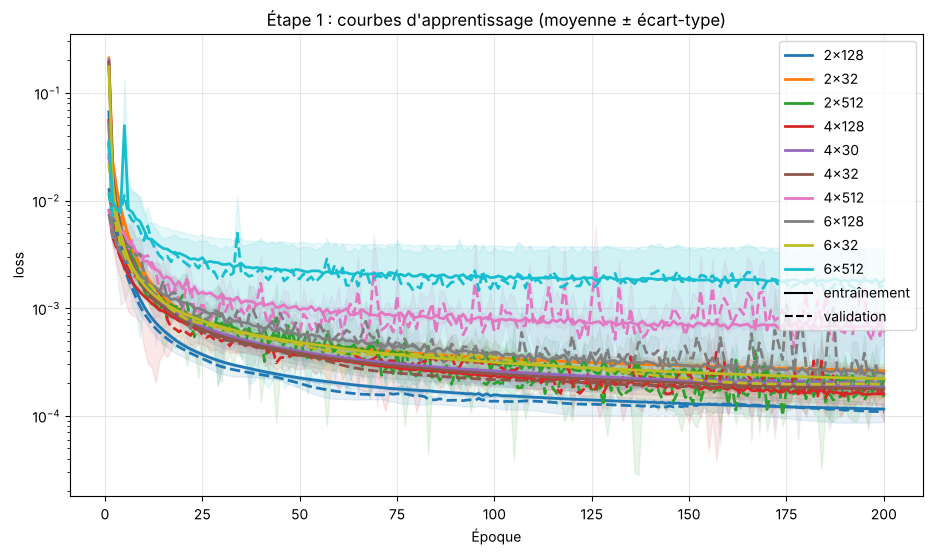

,n_seeds,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,n_params,training_time_s,time_ms,gain
name,,,,,,,,,,
etape1_arch_2x512,5,4.67,0.42,4.67,0.42,172.60,310872,606.01,0.39,5.86
etape1_arch_2x128,5,5.09,0.52,5.09,0.48,161.41,28632,110.21,0.03,82.67
etape1_arch_4x128,5,5.45,0.33,5.45,0.35,144.82,61656,163.03,0.05,44.81
etape1_arch_6x128,5,5.90,0.26,5.89,0.26,132.33,94680,218.22,0.07,30.78
etape1_arch_4x32,5,6.52,1.07,6.49,1.02,164.26,6264,111.96,0.02,99.13
etape1_arch_4x30,5,6.75,0.67,6.77,0.66,149.68,5698,101.48,0.02,99.57
etape1_arch_6x32,5,6.75,0.78,6.78,0.81,144.82,8376,138.36,0.03,72.01
etape1_arch_2x32,5,7.63,0.86,7.64,0.85,249.08,4152,87.05,0.02,113.37
etape1_arch_4x512,5,7.90,1.20,7.90,1.20,144.91,836184,1393.53,1.18,1.94


In [8]:
results = collect_results(1)
print(len(results), "entraînements trouvés sur 50")

short_names = [{**r, "type": r["type"].removeprefix("etape1_arch_")} for r in results]   # légende lisible
show_results(short_names, metric_name="loss", title="Étape 1 : courbes d'apprentissage (moyenne ± écart-type)",
             save_path=repo_path("results", "figures", "etape1_courbes.png"))
plt.show()

timing = pd.read_csv(repo_path("results", "etape1_temps.csv"), index_col="name")
table = summarize(results).join(timing)        # erreurs (moyenne et écart-type sur les graines) + temps
table.round(2)

## 6. Seuil de vitesse et choix de l'architecture
Le seuil est choisi en regardant uniquement les temps (section 4) : au moins **10 fois plus rapide que
Fourier** (`speed_threshold` dans `configs/base.yaml`). Il élimine les trois réseaux de 512 neurones, à peine plus
rapides que Fourier (1,1 à 5,9 fois).

**Règle de choix :** parmi les architectures assez rapides, nous partons de la plus précise sur la validation.
Avec 5 graines, une différence inférieure à un écart-type n'est pas significative : parmi les architectures
à moins d'un écart-type de la plus précise, nous retenons la plus rapide.

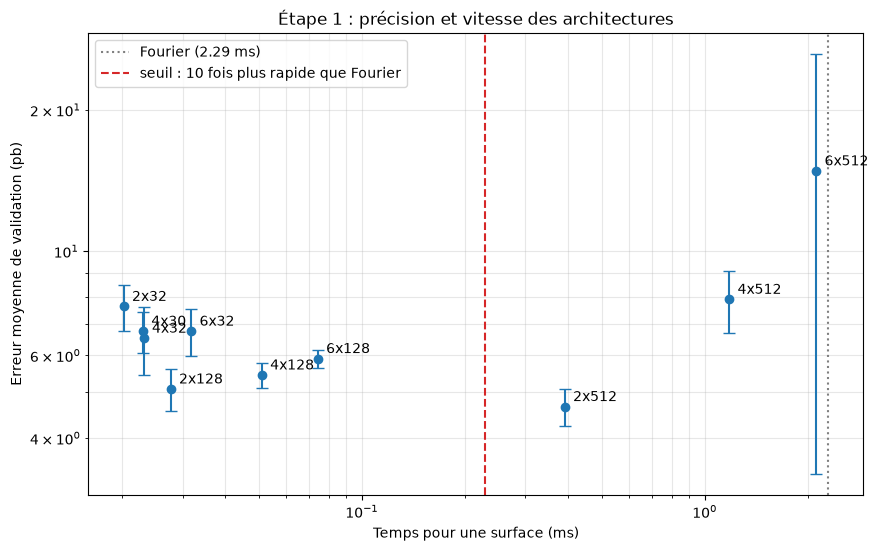

seuil : 10 -> 7 architectures assez rapides
la plus précise : etape1_arch_2x128 ; à moins d'un écart-type (5.60 pb) : ['etape1_arch_2x128', 'etape1_arch_4x128']
architecture retenue : etape1_arch_2x128


,val_mean_bp,val_mean_bp_std,test_mean_bp,test_mean_bp_std,test_max_bp,time_ms,gain,n_params
name,,,,,,,,
etape1_arch_2x128,5.09,0.52,5.09,0.48,161.41,0.03,82.67,28632
etape1_arch_4x128,5.45,0.33,5.45,0.35,144.82,0.05,44.81,61656


In [9]:
cfg = load_config("configs/base.yaml")       # on relit la config, pour prendre le seuil écrit dans base.yaml
threshold = cfg["speed_threshold"]

plot_error_vs_time(table, t_fourier, threshold,
                   save_path=repo_path("results", "figures", "etape1_erreur_temps.png"))
plt.show()

fast_enough = table if threshold is None else table[table["gain"] >= threshold]
most_accurate = fast_enough["val_mean_bp"].idxmin()                        # la plus précise (validation)
limit = fast_enough.loc[most_accurate, "val_mean_bp"] + fast_enough.loc[most_accurate, "val_mean_bp_std"]
close = fast_enough[fast_enough["val_mean_bp"] <= limit]                   # à moins d'un écart-type d'elle
best = close["gain"].idxmax()                                              # parmi elles, la plus rapide

print(f"seuil : {threshold} -> {len(fast_enough)} architectures assez rapides")
print(f"la plus précise : {most_accurate} ; à moins d'un écart-type ({limit:.2f} pb) : {list(close.index)}")
print(f"architecture retenue : {best}")
close[["val_mean_bp", "val_mean_bp_std", "test_mean_bp", "test_mean_bp_std",
       "test_max_bp", "time_ms", "gain", "n_params"]].round(2)

Parmi les architectures assez rapides, le 2 × 128 est le plus précis (5,09 ± 0,52 pb). Le 4 × 128 est à moins d'un
écart-type (5,45 pb), mais presque deux fois plus lent : c'est le 2 × 128 qui est retenu, 83 fois plus rapide que
Fourier. Le 2 × 512, plus précis (4,67 pb), est éliminé par le seuil : il n'est que 5,9 fois plus rapide que Fourier.

## Conclusion
Nous retenons l'architecture à **2 couches de 128 neurones** (5,09 ± 0,52 pb sur la validation, 5,09 pb sur le
test, 83 fois plus rapide que Fourier), et ce pour plusieurs raisons observées dans ce notebook.

- **Les réseaux plus gros ne sont pas meilleurs.** Les réseaux de 512 neurones sur 4 et 6 couches sont à la fois
  plus lents et moins précis, et ils sont aussi instables d'une graine à l'autre (6 × 512 : 14,8 ± 11,5 pb).
- **Le compromis précision / vitesse est net.** Le 2 × 512 est le plus précis (4,67 pb), mais il est 14 fois plus
  lent que le 2 × 128 et seulement 5,9 fois plus rapide que Fourier, pour un gain de 0,4 pb.
- **La largeur compte plus que la profondeur.** À 128 neurones, 2 couches font mieux que 4 et 6 ; à 32 neurones,
  toutes les profondeurs se valent (6,5 à 7,6 pb).
- **Notre choix bat la référence.** Le réseau 4 × 30 de Horvath et al. fait 6,8 pb : le 2 × 128 fait mieux, pour
  un temps de réponse comparable (0,03 ms contre 0,02 ms pour une surface).

Enfin, la validation et le test donnent les mêmes erreurs : il n'y a pas de surapprentissage. La meilleure époque
se situe souvent entre 170 et 200 : avec plus d'époques, les réseaux progresseraient encore un peu.